<a href="https://colab.research.google.com/github/Keerthi786/AI_Builder_Cup_Sustainability-Social-Impact/blob/main/CNN_Builtup_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import required libaries
import os
import numpy as np
import matplotlib.pyplot as plt
import rasterio

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    jaccard_score,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras import layers, models

In [ ]:
# Upload data into notebook
from google.colab import files

uploaded = files.upload()

Saving Builtup_CNN_Data.zip to Builtup_CNN_Data.zip


In [ ]:
# Extract zip file
import zipfile
import os

zip_path = "/content/Builtup_CNN_Data.zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset extracted successfully.")

Dataset extracted successfully.


In [ ]:
DATA_DIR = "/content/Builtup_CNN_Data"

TRAIN_IMAGE_PATH = os.path.join(
    DATA_DIR,
    "Training",
    "Dehradun_S2.tif"
)

TRAIN_LABEL_PATH = os.path.join(
    DATA_DIR,
    "Training",
    "Dehradun_Label.tif"
)

TEST_IMAGE_PATH = os.path.join(
    DATA_DIR,
    "Testing",
    "Lucknow_S2.tif"
)

TEST_LABEL_PATH = os.path.join(
    DATA_DIR,
    "Testing",
    "Lucknow_Label.tif"
)

print("Training image:", TRAIN_IMAGE_PATH)
print("Training label:", TRAIN_LABEL_PATH)
print("Testing image:", TEST_IMAGE_PATH)
print("Testing label:", TEST_LABEL_PATH)

Training image: /content/Builtup_CNN_Data/Training/Dehradun_S2.tif
Training label: /content/Builtup_CNN_Data/Training/Dehradun_Label.tif
Testing image: /content/Builtup_CNN_Data/Testing/Lucknow_S2.tif
Testing label: /content/Builtup_CNN_Data/Testing/Lucknow_Label.tif


In [ ]:
# Check training and test files
files_to_check = [
    TRAIN_IMAGE_PATH,
    TRAIN_LABEL_PATH,
    TEST_IMAGE_PATH,
    TEST_LABEL_PATH
]

for file_path in files_to_check:
    print(
        os.path.basename(file_path),
        "->",
        "Found" if os.path.exists(file_path) else "NOT FOUND"
    )

Dehradun_S2.tif -> Found
Dehradun_Label.tif -> Found
Lucknow_S2.tif -> Found
Lucknow_Label.tif -> Found


In [ ]:
# Read the Dehradun training data
with rasterio.open(TRAIN_IMAGE_PATH) as src:
    train_image = src.read()
    train_profile = src.profile

with rasterio.open(TRAIN_LABEL_PATH) as src:
    train_label = src.read(1)

print("Training image shape:", train_image.shape)
print("Training label shape:", train_label.shape)

Training image shape: (4, 557, 557)
Training label shape: (557, 557)


In [ ]:
band_names = [
    "B2 - Blue",
    "B3 - Green",
    "B4 - Red",
    "B8 - NIR"
]

for i, name in enumerate(band_names):
    print(f"Band {i+1}: {name}")

Band 1: B2 - Blue
Band 2: B3 - Green
Band 3: B4 - Red
Band 4: B8 - NIR


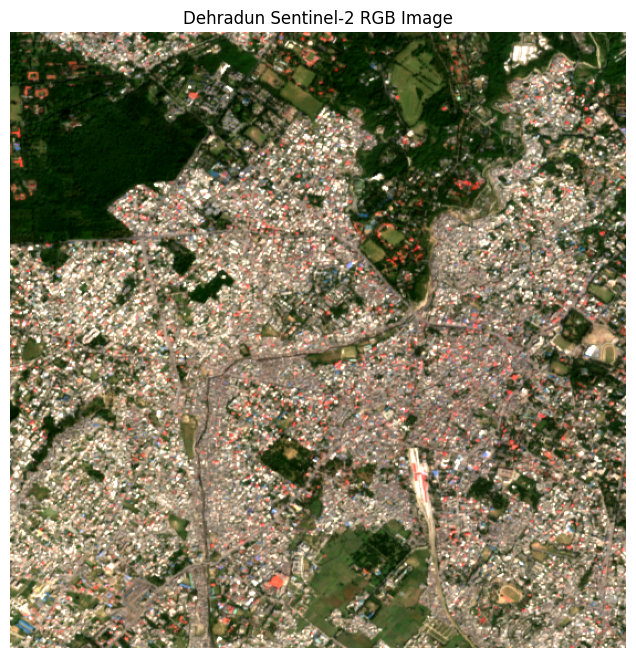

In [ ]:
# Visualize Image (RGB)
rgb = np.stack([
    train_image[2],
    train_image[1],
    train_image[0]
], axis=-1)

# Percentile stretch for visualization
rgb_min = np.percentile(rgb, 2)
rgb_max = np.percentile(rgb, 98)

rgb_display = np.clip(
    (rgb - rgb_min) / (rgb_max - rgb_min),
    0,
    1
)

plt.figure(figsize=(8, 8))
plt.imshow(rgb_display)
plt.title("Dehradun Sentinel-2 RGB Image")
plt.axis("off")
plt.show()

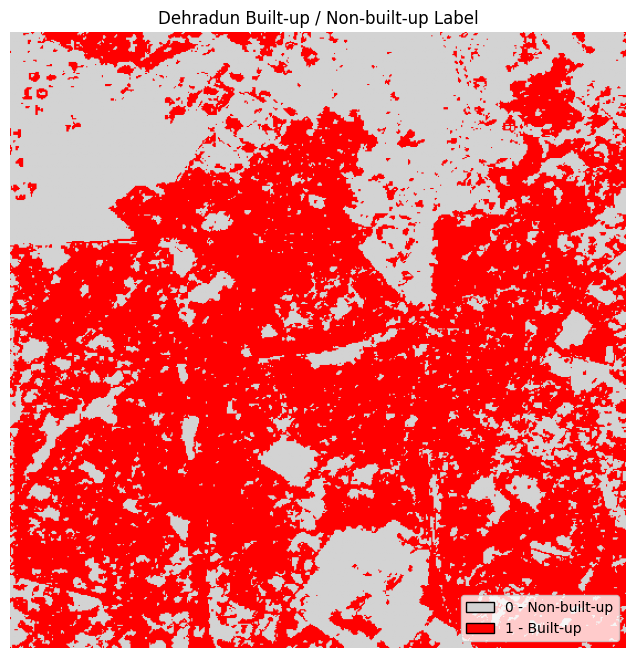

In [ ]:
# Visualize Label
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Define two discrete colors
label_cmap = ListedColormap([
    "lightgray",   # 0 = Non-built-up
    "red"          # 1 = Built-up
])

plt.figure(figsize=(8, 8))

plt.imshow(
    train_label,
    cmap=label_cmap,
    vmin=0,
    vmax=1
)

# Discrete legend
legend_elements = [
    Patch(
        facecolor="lightgray",
        edgecolor="black",
        label="0 - Non-built-up"
    ),
    Patch(
        facecolor="red",
        edgecolor="black",
        label="1 - Built-up"
    )
]

plt.legend(
    handles=legend_elements,
    loc="lower right"
)

plt.title("Dehradun Built-up / Non-built-up Label")
plt.axis("off")
plt.show()

In [ ]:
# Check class distribution
unique, counts = np.unique(
    train_label,
    return_counts=True
)

for value, count in zip(unique, counts):

    percentage = (
        count / train_label.size
    ) * 100

    if value == 0:
        class_name = "Non-built-up"
    elif value == 1:
        class_name = "Built-up"
    else:
        class_name = f"Unknown ({value})"

    print(
        f"Class {value} ({class_name}): "
        f"{count:,} pixels "
        f"({percentage:.2f}%)"
    )

Class 0 (Non-built-up): 122,551 pixels (39.50%)
Class 1 (Built-up): 187,698 pixels (60.50%)


In [ ]:
# Convert image to float32
train_image = train_image.astype(np.float32)

# Create normalized image
train_image_normalized = np.zeros_like(train_image, dtype=np.float32)

for i in range(train_image.shape[0]):

    band = train_image[i]

    # Calculate 2nd and 98th percentiles
    p2 = np.percentile(band, 2)
    p98 = np.percentile(band, 98)

    # Min-max normalization with percentile limits
    normalized = (band - p2) / (p98 - p2)

    # Limit values to 0-1
    normalized = np.clip(normalized, 0, 1)

    train_image_normalized[i] = normalized

In [ ]:
# Transpose dimensions becasue CNN takes (Height, Width, 4) this form
train_image_cnn = np.transpose(
    train_image_normalized,
    (1, 2, 0)
)

print("Original format:", train_image_normalized.shape)
print("CNN format:", train_image_cnn.shape)

Original format: (4, 557, 557)
CNN format: (557, 557, 4)


In [ ]:
# Define patch size

PATCH_SIZE = 64
STRIDE = 32

print("Patch size:", PATCH_SIZE, "×", PATCH_SIZE)
print("Stride:", STRIDE)
print(
    "Ground coverage of each patch:",
    PATCH_SIZE * 10,
    "m ×",
    PATCH_SIZE * 10,
    "m"
)

Patch size: 64 × 64
Stride: 32
Ground coverage of each patch: 640 m × 640 m


In [ ]:
# Create Patch function
def create_patches(
    image,
    label,
    patch_size=64,
    stride=32
):

    image_patches = []
    label_patches = []

    height, width, bands = image.shape

    for row in range(
        0,
        height - patch_size + 1,
        stride
    ):

        for col in range(
            0,
            width - patch_size + 1,
            stride
        ):

            image_patch = image[
                row:row + patch_size,
                col:col + patch_size,
                :
            ]

            label_patch = label[
                row:row + patch_size,
                col:col + patch_size
            ]

            image_patches.append(image_patch)
            label_patches.append(label_patch)

    return (
        np.array(image_patches, dtype=np.float32),
        np.array(label_patches, dtype=np.float32)
    )

In [ ]:
# Generate Dehradun patches
X, y = create_patches(
    train_image_cnn,
    train_label,
    patch_size=PATCH_SIZE,
    stride=STRIDE
)

print("Image patches shape:", X.shape)
print("Label patches shape:", y.shape)
print("Number of patches:", len(X))

Image patches shape: (256, 64, 64, 4)
Label patches shape: (256, 64, 64)
Number of patches: 256


In [ ]:
# Check patch shapes
print("Number of patches:", len(X))
print("Each image patch:", X.shape[1:])
print("Each label patch:", y.shape[1:])

Number of patches: 256
Each image patch: (64, 64, 4)
Each label patch: (64, 64)


In [ ]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    shuffle=True
)

print("Training patches:")
print("  Images:", X_train.shape)
print("  Labels:", y_train.shape)

print("\nValidation patches:")
print("  Images:", X_val.shape)
print("  Labels:", y_val.shape)

Training patches:
  Images: (204, 64, 64, 4)
  Labels: (204, 64, 64)

Validation patches:
  Images: (52, 64, 64, 4)
  Labels: (52, 64, 64)


In [ ]:
# Check class distribution in training and validation patches
# This can be skipped if you have idea that data is correctly balanced
def check_class_distribution(labels, dataset_name):

    unique, counts = np.unique(
        labels,
        return_counts=True
    )

    total_pixels = labels.size

    print(f"\n{dataset_name}")
    print("-" * 40)

    for value, count in zip(unique, counts):

        percentage = (
            count / total_pixels
        ) * 100

        if value == 0:
            class_name = "Non-built-up"
        elif value == 1:
            class_name = "Built-up"
        else:
            class_name = f"Unknown ({value})"

        print(
            f"Class {value} ({class_name}): "
            f"{count:,} pixels "
            f"({percentage:.2f}%)"
        )


check_class_distribution(
    y_train,
    "Training Dataset"
)

check_class_distribution(
    y_val,
    "Validation Dataset"
)


Training Dataset
----------------------------------------
Class 0.0 (Non-built-up): 313,701 pixels (37.54%)
Class 1.0 (Built-up): 521,883 pixels (62.46%)

Validation Dataset
----------------------------------------
Class 0.0 (Non-built-up): 81,879 pixels (38.44%)
Class 1.0 (Built-up): 131,113 pixels (61.56%)


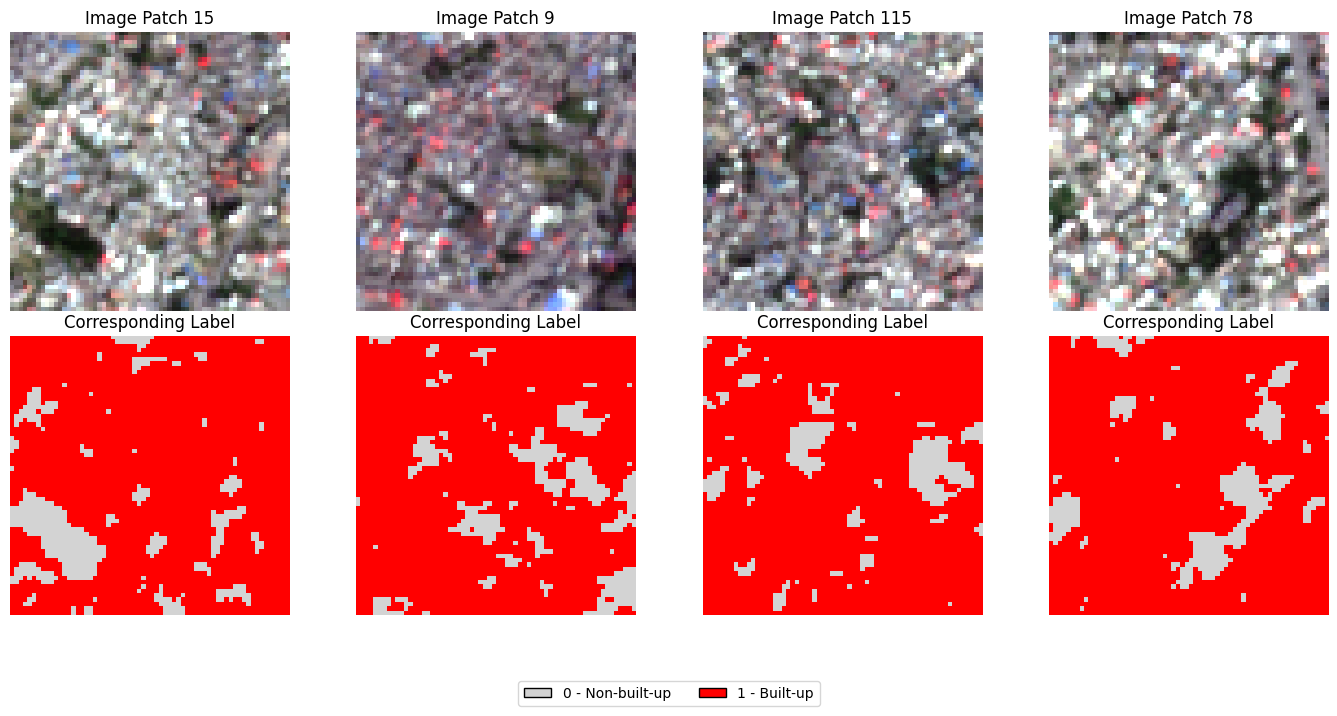

In [ ]:
# Visualize training patches
# Select 4 random training patches
np.random.seed(42)

sample_ids = np.random.choice(
    len(X_train),
    size=4,
    replace=False
)

fig, axes = plt.subplots(
    2, 4,
    figsize=(14, 7)
)

for i, patch_id in enumerate(sample_ids):

    # -----------------------------
    # RGB image patch
    # -----------------------------
    rgb_patch = X_train[patch_id][:, :, [2, 1, 0]]

    axes[0, i].imshow(rgb_patch)
    axes[0, i].set_title(
        f"Image Patch {patch_id}"
    )
    axes[0, i].axis("off")

    # -----------------------------
    # Corresponding label patch
    # -----------------------------
    axes[1, i].imshow(
        y_train[patch_id].squeeze(),
        cmap=label_cmap,
        vmin=0,
        vmax=1
    )

    axes[1, i].set_title(
        "Corresponding Label"
    )
    axes[1, i].axis("off")


# -----------------------------
# Create discrete legend
# -----------------------------
legend_elements = [
    Patch(
        facecolor="lightgray",
        edgecolor="black",
        label="0 - Non-built-up"
    ),
    Patch(
        facecolor="red",
        edgecolor="black",
        label="1 - Built-up"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout()
plt.subplots_adjust(
    bottom=0.12
)

plt.show()

In [ ]:
# Add one channel dimension to the labels

y_train = np.expand_dims(
    y_train,
    axis=-1
)

y_val = np.expand_dims(
    y_val,
    axis=-1
)

print("Training labels:", y_train.shape)
print("Validation labels:", y_val.shape)

Training labels: (204, 64, 64, 1)
Validation labels: (52, 64, 64, 1)


In [ ]:
print("CNN INPUT")
print("Training images   :", X_train.shape)
print("Validation images :", X_val.shape)

print("\nCNN TARGET")
print("Training labels   :", y_train.shape)
print("Validation labels :", y_val.shape)

CNN INPUT
Training images   : (204, 64, 64, 4)
Validation images : (52, 64, 64, 4)

CNN TARGET
Training labels   : (204, 64, 64, 1)
Validation labels : (52, 64, 64, 1)


In [ ]:
# Build CNN Model
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(64, 64, 4)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.UpSampling2D((2, 2)),

    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        1, (1, 1),
        activation="sigmoid",
        padding="same"
    )
])

In [ ]:
# Model summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │         1,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 1)      │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 84,353 (329.50 KB)

 Trainable params: 84,353 (329.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compile CNN model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [ ]:
#gpus = tf.config.list_physical_devices("GPU")

#if gpus:
    #print("GPU detected.")
    #print("Training will use GPU.")
    #print("GPU:", gpus[0].name)
#else:
    #print("No GPU detected.")
    #print("Training will use CPU.")

In [ ]:
# Set training parameters
EPOCHS = 30
BATCH_SIZE = 8

print("Epochs:", EPOCHS)
print("Batch size:", BATCH_SIZE)

from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Early stopping configured.")

Epochs: 30
Batch size: 8
Early stopping configured.


In [ ]:
# Train the CNN model
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 321ms/step - accuracy: 0.8387 - loss: 0.3794 - val_accuracy: 0.9073 - val_loss: 0.2456
Epoch 2/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 269ms/step - accuracy: 0.9012 - loss: 0.2545 - val_accuracy: 0.9152 - val_loss: 0.2189
Epoch 3/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 282ms/step - accuracy: 0.9069 - loss: 0.2393 - val_accuracy: 0.9187 - val_loss: 0.2084
Epoch 4/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 11s 313ms/step - accuracy: 0.9112 - loss: 0.2262 - val_accuracy: 0.9201 - val_loss: 0.2050
Epoch 5/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 7s 259ms/step - accuracy: 0.9114 - loss: 0.2254 - val_accuracy: 0.9211 - val_loss: 0.2001
Epoch 6/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 8s 305ms/step - accuracy: 0.9133 - loss: 0.2203 - val_accuracy: 0.9231 - val_loss: 0.1938
Epoch 7/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 10s 302ms/step - accuracy: 0.9155 - loss: 0.2135 - val_accuracy: 0.9237 - val_loss: 0.1936
Epoch 8/30
26/26 ━━━━━━━━━━━━━━━━━━━━ 6s 249ms/step - accuracy: 0.9151 - loss: 0.2145 - val_accuracy:

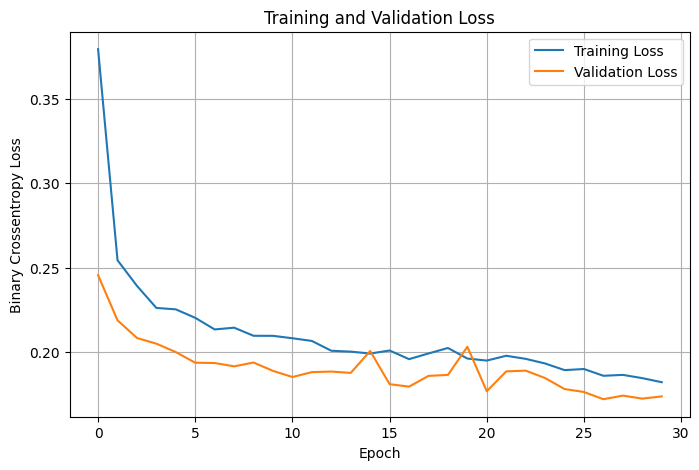

In [ ]:
# Plot Training and Validation Loss
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Crossentropy Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)
plt.show()

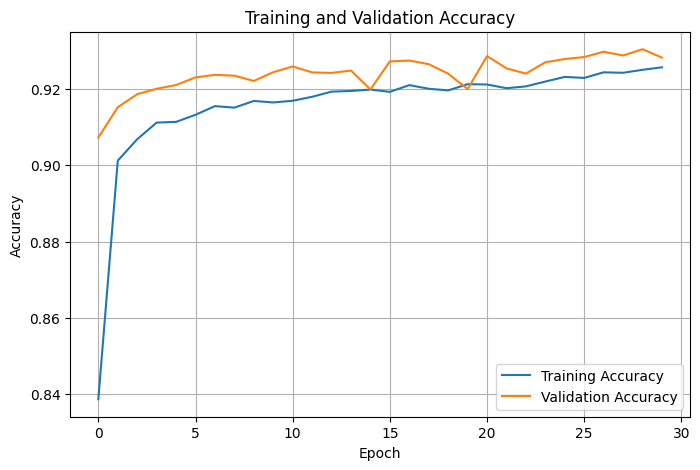

In [ ]:
# Plot Training and Validation Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Predict the validation patches
y_val_pred_prob = model.predict(
    X_val,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("Prediction shape:", y_val_pred_prob.shape)

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 78ms/step
Prediction shape: (52, 64, 64, 1)


In [ ]:
# Convert probabilities to binary predictions
THRESHOLD = 0.5

y_val_pred = (
    y_val_pred_prob >= THRESHOLD
).astype(np.uint8)

print("Predicted label shape:", y_val_pred.shape)
print("Unique predicted values:", np.unique(y_val_pred))

Predicted label shape: (52, 64, 64, 1)
Unique predicted values: [0 1]


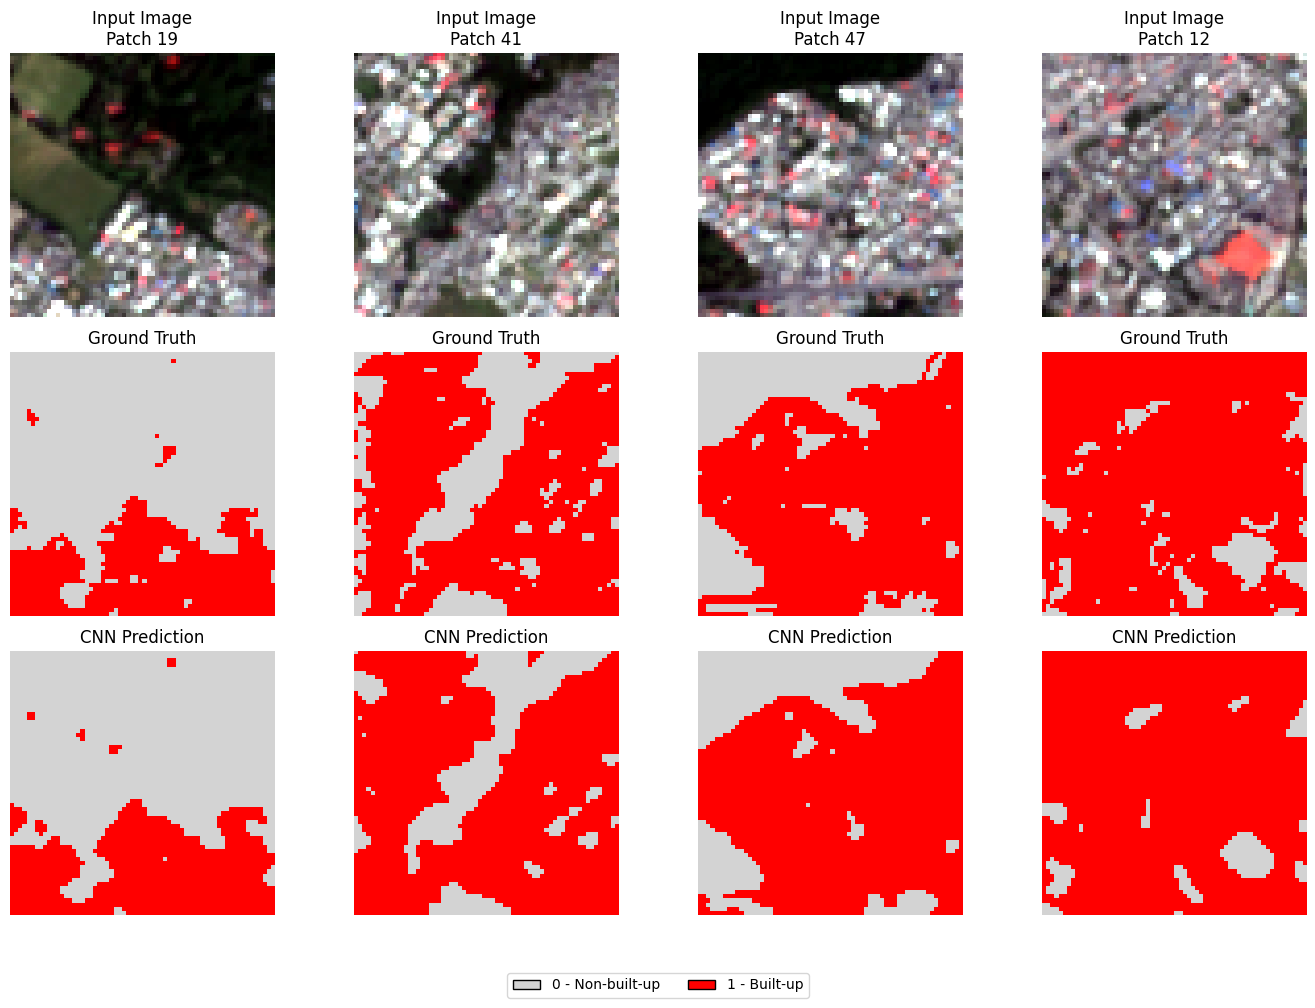

In [ ]:
# Visualize image, ground truth and prediction
from matplotlib.patches import Patch

np.random.seed(42)

sample_ids = np.random.choice(
    len(X_val),
    size=4,
    replace=False
)

fig, axes = plt.subplots(
    3, 4,
    figsize=(14, 10)
)

for i, patch_id in enumerate(sample_ids):

    # RGB image
    rgb_patch = X_val[patch_id][:, :, [2, 1, 0]]

    axes[0, i].imshow(rgb_patch)
    axes[0, i].set_title(
        f"Input Image\nPatch {patch_id}"
    )
    axes[0, i].axis("off")

    # Ground truth
    axes[1, i].imshow(
        y_val[patch_id].squeeze(),
        cmap=label_cmap,
        vmin=0,
        vmax=1
    )
    axes[1, i].set_title("Ground Truth")
    axes[1, i].axis("off")

    # Prediction
    axes[2, i].imshow(
        y_val_pred[patch_id].squeeze(),
        cmap=label_cmap,
        vmin=0,
        vmax=1
    )
    axes[2, i].set_title("CNN Prediction")
    axes[2, i].axis("off")


legend_elements = [
    Patch(
        facecolor="lightgray",
        edgecolor="black",
        label="0 - Non-built-up"
    ),
    Patch(
        facecolor="red",
        edgecolor="black",
        label="1 - Built-up"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.01)
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.08)
plt.show()

In [ ]:
# Calculate validation metrics
# Flatten ground truth and prediction arrays
y_val_true_flat = y_val.squeeze().flatten()
y_val_pred_flat = y_val_pred.squeeze().flatten()

# Calculate metrics
val_accuracy = accuracy_score(
    y_val_true_flat,
    y_val_pred_flat
)

val_precision = precision_score(
    y_val_true_flat,
    y_val_pred_flat,
    zero_division=0
)

val_recall = recall_score(
    y_val_true_flat,
    y_val_pred_flat,
    zero_division=0
)

val_f1 = f1_score(
    y_val_true_flat,
    y_val_pred_flat,
    zero_division=0
)

val_iou = jaccard_score(
    y_val_true_flat,
    y_val_pred_flat,
    zero_division=0
)

print("Validation Metrics")
print("-" * 35)
print(f"Accuracy  : {val_accuracy:.4f}")
print(f"Precision : {val_precision:.4f}")
print(f"Recall    : {val_recall:.4f}")
print(f"F1-score  : {val_f1:.4f}")
print(f"IoU       : {val_iou:.4f}")

Validation Metrics
-----------------------------------
Accuracy  : 0.9298
Precision : 0.9243
Recall    : 0.9650
F1-score  : 0.9442
IoU       : 0.8943


Confusion Matrix
-----------------------------------
[[ 71514  10365]
 [  4589 126524]]


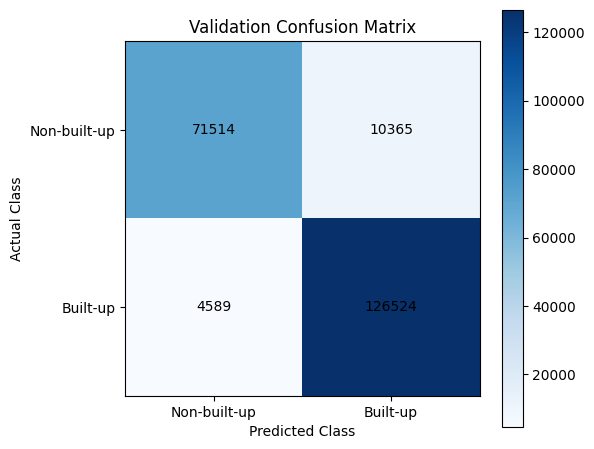

In [ ]:
# Confusion Matrix
cm = confusion_matrix(
    y_val_true_flat,
    y_val_pred_flat
)

print("Confusion Matrix")
print("-" * 35)
print(cm)

plt.figure(figsize=(6, 5))

plt.imshow(
    cm,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("Validation Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Non-built-up", "Built-up"]
)

plt.yticks(
    [0, 1],
    ["Non-built-up", "Built-up"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
# Save the trained model
MODEL_PATH = "/content/builtup_cnn_model.keras"

model.save(MODEL_PATH)

print("Model saved successfully.")
print("Model path:", MODEL_PATH)

Model saved successfully.
Model path: /content/builtup_cnn_model.keras


In [ ]:
# Load the unseen Lucknow Sentinel-2 image

with rasterio.open(TEST_IMAGE_PATH) as src:
    test_image = src.read()
    test_profile = src.profile.copy()

print("Lucknow image loaded successfully.")
print("-" * 40)

print("Image shape:", test_image.shape)
print("Number of bands:", test_image.shape[0])
print("Image height:", test_image.shape[1])
print("Image width:", test_image.shape[2])

print("Coordinate system:", test_profile["crs"])

# Verify that the image has the four bands
# expected by our trained CNN.

assert test_image.shape[0] == 4, (
    "The CNN requires four Sentinel-2 bands: "
    "B2, B3, B4 and B8."
)

Lucknow image loaded successfully.
----------------------------------------
Image shape: (4, 557, 557)
Number of bands: 4
Image height: 557
Image width: 557
Coordinate system: EPSG:4326


In [ ]:
# Normalize the unseen Lucknow image
# using statistics derived from the training image

test_image = test_image.astype(np.float32)

test_image_normalized = np.zeros_like(
    test_image,
    dtype=np.float32
)

for i in range(test_image.shape[0]):

    # Calculate normalization statistics
    # from the Dehradun training image
    train_band = train_image[i]

    p2 = np.percentile(train_band, 2)
    p98 = np.percentile(train_band, 98)

    # Apply the same transformation to Lucknow
    normalized = (
        test_image[i] - p2
    ) / (p98 - p2)

    normalized = np.clip(
        normalized,
        0,
        1
    )

    test_image_normalized[i] = normalized

print("Lucknow image normalization completed.")

Lucknow image normalization completed.


In [ ]:
# Create patches for test image
def create_image_patches(
    image,
    patch_size=64,
    stride=32
):
    image_patches = []
    patch_positions = []

    height, width, bands = image.shape

    # Generate row positions
    row_positions = list(
        range(0, height - patch_size + 1, stride)
    )

    # Make sure the bottom edge is covered
    if row_positions[-1] != height - patch_size:
        row_positions.append(height - patch_size)

    # Generate column positions
    col_positions = list(
        range(0, width - patch_size + 1, stride)
    )

    # Make sure the right edge is covered
    if col_positions[-1] != width - patch_size:
        col_positions.append(width - patch_size)

    # Extract patches
    for row in row_positions:
        for col in col_positions:

            image_patch = image[
                row:row + patch_size,
                col:col + patch_size,
                :
            ]

            image_patches.append(image_patch)
            patch_positions.append((row, col))

    return (
        np.array(image_patches, dtype=np.float32),
        patch_positions
    )

# Convert Lucknow image from
# (bands, height, width)
# to
# (height, width, bands)

test_image_cnn = np.transpose(
    test_image_normalized,
    (1, 2, 0)
)

print("Lucknow CNN image shape:", test_image_cnn.shape)
X_lucknow, lucknow_positions = create_image_patches(
    test_image_cnn,
    patch_size=PATCH_SIZE,
    stride=STRIDE
)

print("Lucknow patches created.")
print("-" * 40)
print("Patch array shape:", X_lucknow.shape)
print("Number of patches:", len(X_lucknow))
print("Patch size:", PATCH_SIZE)
print("Stride:", STRIDE)

Lucknow CNN image shape: (557, 557, 4)
Lucknow patches created.
----------------------------------------
Patch array shape: (289, 64, 64, 4)
Number of patches: 289
Patch size: 64
Stride: 32


In [ ]:
# Predict built-up probability for all Lucknow patches

lucknow_pred_prob = model.predict(
    X_lucknow,
    batch_size=BATCH_SIZE,
    verbose=1
)

print("Prediction completed.")
print("Prediction shape:", lucknow_pred_prob.shape)
print(
    "Probability range:",
    lucknow_pred_prob.min(),
    "to",
    lucknow_pred_prob.max()
)

37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 57ms/step
Prediction completed.
Prediction shape: (289, 64, 64, 1)
Probability range: 2.7329997e-07 to 0.99968284


In [ ]:
# Convert probabilities into binary predictions
THRESHOLD = 0.5

lucknow_pred = (
    lucknow_pred_prob >= THRESHOLD
).astype(np.uint8)

print("Binary prediction created.")
print("Prediction shape:", lucknow_pred.shape)
print("Unique values:", np.unique(lucknow_pred))

Binary prediction created.
Prediction shape: (289, 64, 64, 1)
Unique values: [0 1]


In [ ]:
# Reconstruct the complete Lucknow prediction
# by averaging probabilities in overlapping patches

height, width = test_image_cnn.shape[:2]

probability_sum = np.zeros(
    (height, width),
    dtype=np.float32
)

pixel_count = np.zeros(
    (height, width),
    dtype=np.float32
)

for patch_id, (row, col) in enumerate(lucknow_positions):

    patch_probability = lucknow_pred_prob[
        patch_id
    ].squeeze()

    probability_sum[
        row:row + PATCH_SIZE,
        col:col + PATCH_SIZE
    ] += patch_probability

    pixel_count[
        row:row + PATCH_SIZE,
        col:col + PATCH_SIZE
    ] += 1


# Calculate average probability
lucknow_probability_map = (
    probability_sum / pixel_count
)

print("Lucknow probability map reconstructed.")
print("-" * 40)
print("Map shape:", lucknow_probability_map.shape)
print(
    "Probability range:",
    lucknow_probability_map.min(),
    "to",
    lucknow_probability_map.max()
)

Lucknow probability map reconstructed.
----------------------------------------
Map shape: (557, 557)
Probability range: 2.7329997e-07 to 0.9994428


In [ ]:
# Create final Lucknow prediction map
# Convert probability map into binary classes

lucknow_prediction_map = (
    lucknow_probability_map >= THRESHOLD
).astype(np.uint8)

print("Final Lucknow prediction map created.")
print("-" * 40)
print("Map shape:", lucknow_prediction_map.shape)
print("Unique classes:", np.unique(lucknow_prediction_map))

# Count pixels in each class
unique, counts = np.unique(
    lucknow_prediction_map,
    return_counts=True
)

print("\nPredicted class distribution:")

for value, count in zip(unique, counts):

    percentage = (
        count / lucknow_prediction_map.size
    ) * 100

    if value == 0:
        class_name = "Non-built-up"
    else:
        class_name = "Built-up"

    print(
        f"Class {value} ({class_name}): "
        f"{count:,} pixels "
        f"({percentage:.2f}%)"
    )

Final Lucknow prediction map created.
----------------------------------------
Map shape: (557, 557)
Unique classes: [0 1]

Predicted class distribution:
Class 0 (Non-built-up): 233,497 pixels (75.26%)
Class 1 (Built-up): 76,752 pixels (24.74%)


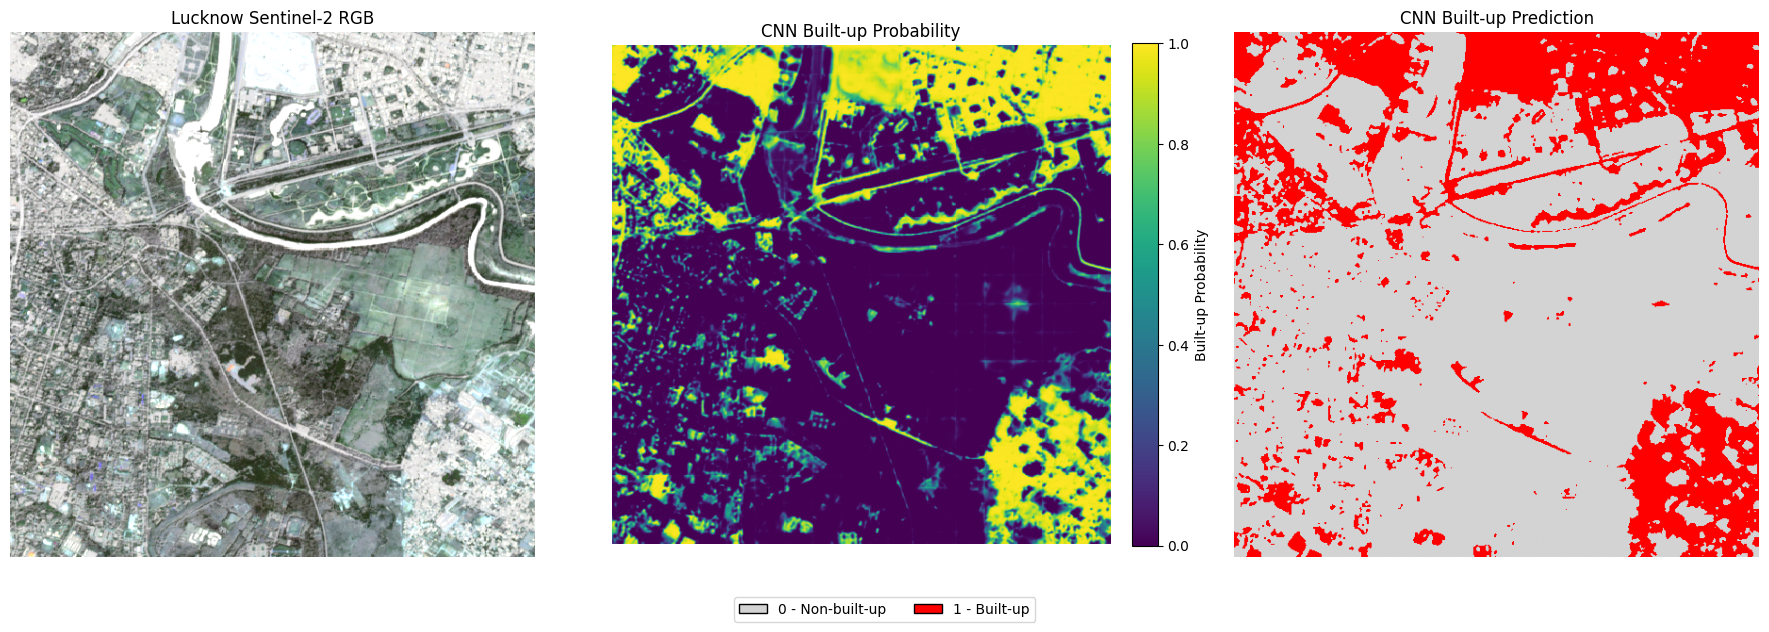

In [ ]:
# Visualize test image, probability map,
# and binary CNN prediction

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

# --------------------------------------------------
# 1. RGB image
# --------------------------------------------------

axes[0].imshow(test_image_cnn)

axes[0].set_title(
    "Lucknow Sentinel-2 RGB"
)

axes[0].axis("off")


# --------------------------------------------------
# 2. CNN probability map
# --------------------------------------------------

probability_image = axes[1].imshow(
    lucknow_probability_map,
    cmap="viridis",
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "CNN Built-up Probability"
)

axes[1].axis("off")

cbar = fig.colorbar(
    probability_image,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)

cbar.set_label(
    "Built-up Probability"
)


# --------------------------------------------------
# 3. CNN binary prediction
# --------------------------------------------------

axes[2].imshow(
    lucknow_prediction_map,
    cmap=label_cmap,
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "CNN Built-up Prediction"
)

axes[2].axis("off")


# --------------------------------------------------
# Common legend for binary maps
# --------------------------------------------------

legend_elements = [
    Patch(
        facecolor="lightgray",
        edgecolor="black",
        label="0 - Non-built-up"
    ),
    Patch(
        facecolor="red",
        edgecolor="black",
        label="1 - Built-up"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.10)

plt.show()

In [ ]:
# Load Lucknow reference label
# This label has NOT been used during prediction.

with rasterio.open(TEST_LABEL_PATH) as src:
    lucknow_label = src.read(1)

print("Lucknow reference label loaded.")
print("-" * 40)
print("Label shape:", lucknow_label.shape)
print("Unique values:", np.unique(lucknow_label))

Lucknow reference label loaded.
----------------------------------------
Label shape: (557, 557)
Unique values: [0 1]


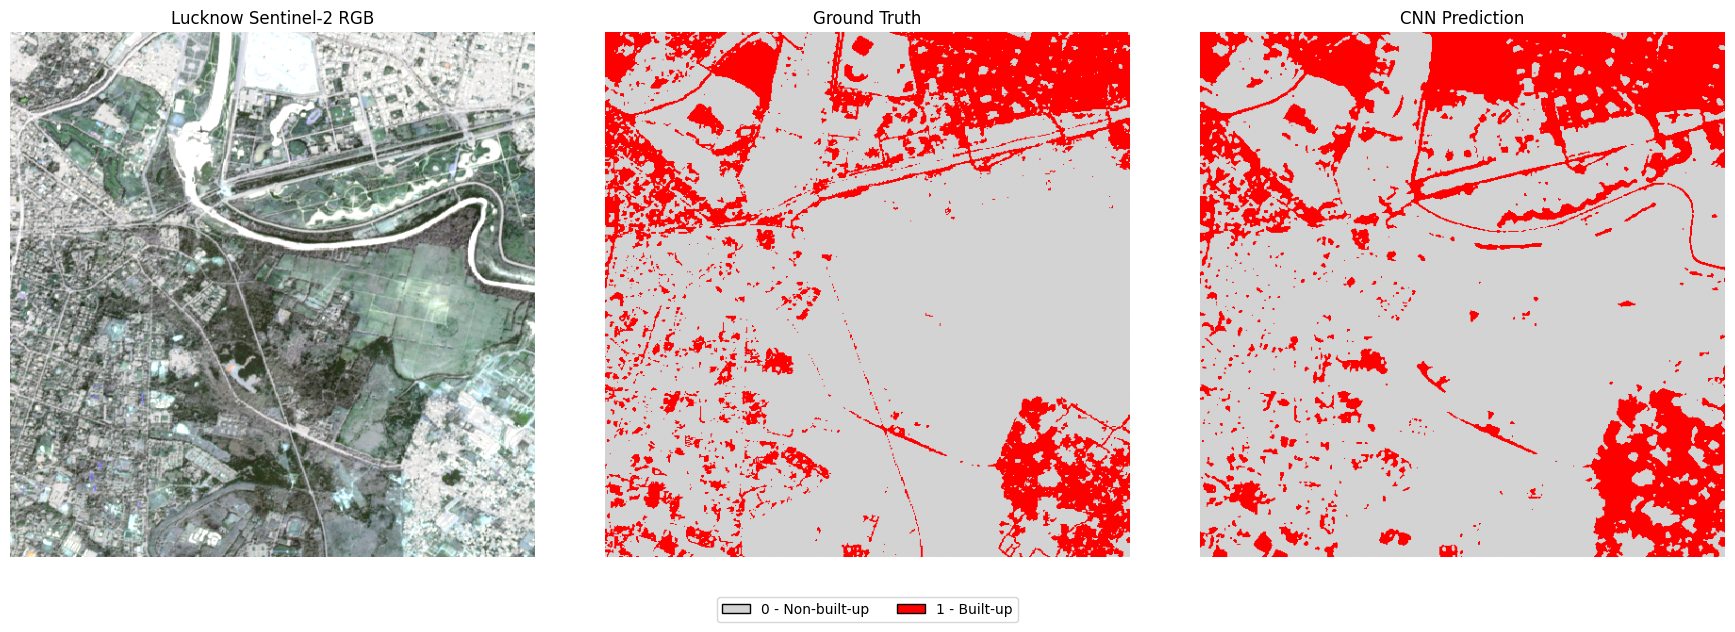

In [ ]:
# Visual comparison:
# RGB | Ground Truth | CNN Prediction

fig, axes = plt.subplots(
    1, 3,
    figsize=(18, 6)
)

# --------------------------------------------------
# 1. RGB image
# --------------------------------------------------

axes[0].imshow(test_image_cnn)

axes[0].set_title(
    "Lucknow Sentinel-2 RGB"
)

axes[0].axis("off")


# --------------------------------------------------
# 2. Ground Truth
# --------------------------------------------------

axes[1].imshow(
    lucknow_label,
    cmap=label_cmap,
    vmin=0,
    vmax=1
)

axes[1].set_title(
    "Ground Truth"
)

axes[1].axis("off")


# --------------------------------------------------
# 3. CNN Prediction
# --------------------------------------------------

axes[2].imshow(
    lucknow_prediction_map,
    cmap=label_cmap,
    vmin=0,
    vmax=1
)

axes[2].set_title(
    "CNN Prediction"
)

axes[2].axis("off")


# --------------------------------------------------
# SAME legend for both maps
# --------------------------------------------------

legend_elements = [
    Patch(
        facecolor="lightgray",
        edgecolor="black",
        label="0 - Non-built-up"
    ),
    Patch(
        facecolor="red",
        edgecolor="black",
        label="1 - Built-up"
    )
]

fig.legend(
    handles=legend_elements,
    loc="lower center",
    ncol=2,
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout()
plt.subplots_adjust(bottom=0.10)

plt.show()

In [ ]:
# Calculate test image statistics
# Flatten the Lucknow ground truth and CNN prediction

y_lucknow_true_flat = lucknow_label.flatten()
y_lucknow_pred_flat = lucknow_prediction_map.flatten()

# Calculate evaluation metrics

lucknow_accuracy = accuracy_score(
    y_lucknow_true_flat,
    y_lucknow_pred_flat
)

lucknow_precision = precision_score(
    y_lucknow_true_flat,
    y_lucknow_pred_flat,
    zero_division=0
)

lucknow_recall = recall_score(
    y_lucknow_true_flat,
    y_lucknow_pred_flat,
    zero_division=0
)

lucknow_f1 = f1_score(
    y_lucknow_true_flat,
    y_lucknow_pred_flat,
    zero_division=0
)

lucknow_iou = jaccard_score(
    y_lucknow_true_flat,
    y_lucknow_pred_flat,
    zero_division=0
)

print("Lucknow Independent Test Metrics")
print("=" * 40)

print(f"Accuracy  : {lucknow_accuracy:.4f}")
print(f"Precision : {lucknow_precision:.4f}")
print(f"Recall    : {lucknow_recall:.4f}")
print(f"F1-score  : {lucknow_f1:.4f}")
print(f"IoU       : {lucknow_iou:.4f}")

Lucknow Independent Test Metrics
Accuracy  : 0.8835
Precision : 0.7107
Recall    : 0.7963
F1-score  : 0.7511
IoU       : 0.6014


Lucknow Independent Test Confusion Matrix
[[219544  22204]
 [ 13953  54548]]


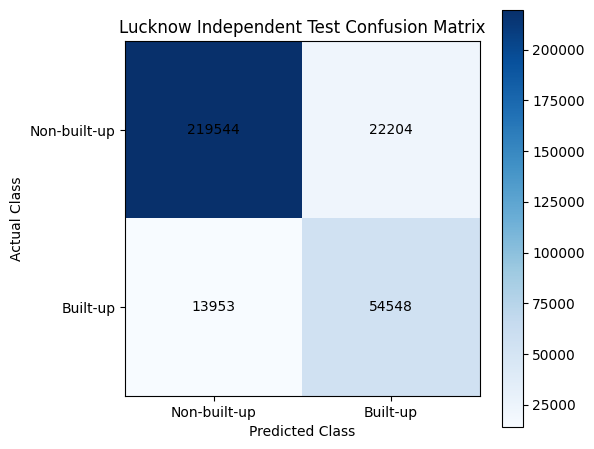

In [ ]:
# Calculate confusion matrix for the independent Lucknow test area

cm_lucknow = confusion_matrix(
    y_lucknow_true_flat,
    y_lucknow_pred_flat
)

print("Lucknow Independent Test Confusion Matrix")
print("=" * 45)
print(cm_lucknow)

plt.figure(figsize=(6, 5))

plt.imshow(
    cm_lucknow,
    interpolation="nearest",
    cmap="Blues"
)

plt.title(
    "Lucknow Independent Test Confusion Matrix"
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(
    [0, 1],
    ["Non-built-up", "Built-up"]
)

plt.yticks(
    [0, 1],
    ["Non-built-up", "Built-up"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            cm_lucknow[i, j],
            ha="center",
            va="center"
        )

plt.colorbar()

plt.tight_layout()
plt.show()

In [ ]:
# Built-up Area Comparison

# Calculate built-up area from the current prediction
# using the nominal Sentinel-2 10 m pixel size

pixel_area_m2 = 10 * 10

# Ground truth
gt_builtup_pixels = np.sum(lucknow_label == 1)
gt_builtup_area_m2 = gt_builtup_pixels * pixel_area_m2
gt_builtup_area_ha = gt_builtup_area_m2 / 10000

# CNN prediction
pred_builtup_pixels = np.sum(lucknow_prediction_map == 1)
pred_builtup_area_m2 = pred_builtup_pixels * pixel_area_m2
pred_builtup_area_ha = pred_builtup_area_m2 / 10000

# Percentages
total_pixels = lucknow_label.size

gt_builtup_percentage = (gt_builtup_pixels / total_pixels) * 100
pred_builtup_percentage = (pred_builtup_pixels / total_pixels) * 100

# Difference
area_difference_ha = pred_builtup_area_ha - gt_builtup_area_ha
percentage_difference = pred_builtup_percentage - gt_builtup_percentage

print("=" * 60)
print("BUILT-UP AREA COMPARISON")
print("=" * 60)

print("\nGround Truth:")
print(f"Built-up pixels      : {gt_builtup_pixels:,}")
print(f"Built-up percentage  : {gt_builtup_percentage:.2f}%")
print(f"Built-up area        : {gt_builtup_area_ha:.2f} ha")

print("\nCNN Prediction:")
print(f"Built-up pixels      : {pred_builtup_pixels:,}")
print(f"Built-up percentage  : {pred_builtup_percentage:.2f}%")
print(f"Built-up area        : {pred_builtup_area_ha:.2f} ha")

print("\nDifference:")
print(f"Area difference      : {area_difference_ha:.2f} ha")
print(f"Percentage difference: {percentage_difference:.2f}%")

BUILT-UP AREA COMPARISON

Ground Truth:
Built-up pixels      : 68,501
Built-up percentage  : 22.08%
Built-up area        : 685.01 ha

CNN Prediction:
Built-up pixels      : 76,752
Built-up percentage  : 24.74%
Built-up area        : 767.52 ha

Difference:
Area difference      : 82.51 ha
Percentage difference: 2.66%


In [ ]:
# Reproject and Export CNN Prediction

import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling

# Output file

OUTPUT_PATH = "/content/Lucknow_CNN_Builtup_Prediction_UTM44N.tif"

# Target CRS:
# UTM Zone 44N
# Suitable for Lucknow and Dehradun
TARGET_CRS = "EPSG:32644"

# Read source raster information


with rasterio.open(TEST_IMAGE_PATH) as src:

    source_crs = src.crs
    source_transform = src.transform
    source_width = src.width
    source_height = src.height

    # Calculate transformation to projected CRS
    transform, width, height = calculate_default_transform(
        source_crs,
        TARGET_CRS,
        source_width,
        source_height,
        *src.bounds
    )

    # Prepare output profile
    output_profile = src.profile.copy()

    output_profile.update(
        crs=TARGET_CRS,
        transform=transform,
        width=width,
        height=height,
        dtype=rasterio.uint8,
        count=1,
        compress="lzw",
        tiled=True,
        blockxsize=256,
        blockysize=256
    )

    # Class 0 is a valid class, so do NOT use 0 as NoData
    output_profile.pop("nodata", None)

    # Create destination raster
    with rasterio.open(OUTPUT_PATH, "w", **output_profile) as dst:

        reproject(
            source=lucknow_prediction_map.astype(np.uint8),
            destination=rasterio.band(dst, 1),
            src_transform=source_transform,
            src_crs=source_crs,
            dst_transform=transform,
            dst_crs=TARGET_CRS,
            resampling=Resampling.nearest
        )


# Verify the projected output

with rasterio.open(OUTPUT_PATH) as src:

    exported_prediction = src.read(1)

    print("EXPORTED CNN PREDICTION")

    print("File:", OUTPUT_PATH)
    print("Shape:", exported_prediction.shape)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Data type:", exported_prediction.dtype)
    print("Unique values:", np.unique(exported_prediction))
    print("NoData value:", src.nodata)

EXPORTED CNN PREDICTION
File: /content/Lucknow_CNN_Builtup_Prediction_UTM44N.tif
Shape: (586, 526)
CRS: EPSG:32644
Resolution: (9.45176597762167, 9.45176597762167)
Data type: uint8
Unique values: [0 1]
NoData value: None
